# PixelHistogram — CPU vs CUDA

Per-pixel histograms of a data file, filled by `PixelHistogram` on the CPU and
by `PixelHistogramCUDA` on the GPU. Times both, then checks that the results are
identical.

In [1]:
import sys; sys.path.append('/home/ferjao_k/aare/build')

import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from aare import File, PixelHistogram_u32, PixelHistogramCUDA

In [2]:
base = Path('/mnt/sls_det_storage/moench_data/2603_MaxIVBeamtime/2026032408/process/xrf/')
f = File(base / 'Cu_factor_10_data_master_0.json')
frames = f.read_n(100_000)          # (n_frames, rows, cols), uint16
n_frames, rows, cols = frames.shape

n_bins, xmin, xmax = 1000, 3500, 7500   # 4 ADU per bin
n_threads = 16                          # CPU threads
print(frames.shape, frames.dtype, f'{frames.nbytes / 1e9:.2f} GB')

(100000, 400, 400) uint16 32.00 GB


## CPU

In [3]:
cpu = PixelHistogram_u32(rows=rows, cols=cols, n_bins=n_bins, xmin=xmin, xmax=xmax,
                         n_threads=n_threads)

t0 = time.perf_counter()
for frame in frames:
    cpu.fill_async(frame.astype(np.float64))   # the CPU binding takes float64
values_cpu = cpu.values()
t_cpu = time.perf_counter() - t0
print(f'CPU: {t_cpu:.2f} s, {n_frames / t_cpu:,.0f} frames/s')

CPU: 21.75 s, 4,598 frames/s


## GPU

In [4]:
gpu = PixelHistogramCUDA(rows=rows, cols=cols, n_bins=n_bins, xmin=xmin, xmax=xmax,
                         dtype=frames.dtype, storage_dtype=np.uint32, batch_size=128)
gpu.register_input_buffer(frames)   # pin once, before the timed loop
values_gpu = np.empty((rows, cols, n_bins), dtype=np.uint32)
gpu.register_output_buffer(values_gpu)

t0 = time.perf_counter()
gpu.fill_histogram(frames)
gpu.flush()                         # fill_histogram only queues the work
t1 = time.perf_counter()
gpu.values(out=values_gpu)          # transpose + copy back to the host
t2 = time.perf_counter()

t_gpu = t2 - t0
print(f'GPU fill:   {t1 - t0:.3f} s, {n_frames / (t1 - t0):,.0f} frames/s, '
      f'{frames.nbytes / (t1 - t0) / 1e9:.1f} GB/s')
print(f'GPU values: {t2 - t1:.3f} s')
print(f'GPU total:  {t_gpu:.3f} s, speed-up {t_cpu / t_gpu:.1f}x')

GPU fill:   1.512 s, 66,119 frames/s, 21.2 GB/s
GPU values: 0.032 s
GPU total:  1.545 s, speed-up 14.1x


## Compare

In [5]:
print('identical:', np.array_equal(values_cpu, values_gpu))
print('counts:   ', values_cpu.sum(), values_gpu.sum())

identical: True
counts:    15997375206 15997375206


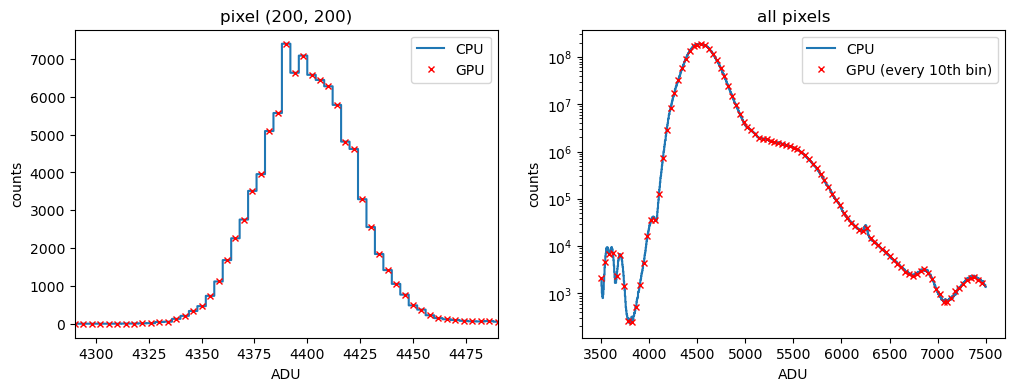

In [6]:
x = gpu.bin_centers()
row, col = rows // 2, cols // 2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.step(x, values_cpu[row, col], where='mid', label='CPU')
ax1.plot(x, values_gpu[row, col], 'rx', ms=5, label='GPU')
ax1.set_xlim(x[values_cpu[row, col].argmax()] + np.array([-100, 100]))
ax1.set(title=f'pixel ({row}, {col})', xlabel='ADU', ylabel='counts')
ax1.legend()

ax2.step(x, values_cpu.sum(axis=(0, 1)), where='mid', label='CPU')
ax2.plot(x, values_gpu.sum(axis=(0, 1)), 'rx', ms=5, markevery=10, label='GPU (every 10th bin)')
ax2.set_yscale('log')
ax2.set(title='all pixels', xlabel='ADU', ylabel='counts')
ax2.legend()
plt.show()